In [1]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold #, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder

## Croosval

In [2]:
# SMOTE está disponivel no pacote imblearn
# TODO estudar mais sobre o imblearn

In [3]:
def validacao_cruzada(modelo, x, y, oversampling=False):
    kfold = KFold(n_splits=5)
    acc_splits = []

    for idx, (idx_treino, idx_validacao) in enumerate(kfold.split(x)):
        x_split_treino = x.iloc[idx_treino, :]
        y_split_treino = y.iloc[idx_treino]

        # oversampling apenas no split de treino
        if oversampling:
            sm = SMOTE(random_state=42)
            x_split_treino, y_split_treino = sm.fit_resample(x_split_treino, y_split_treino)

        x_split_validacao = x.iloc[idx_validacao, :]
        y_split_validacao = y.iloc[idx_validacao]

        # treina modelo  com os dados balanceados
        modelo.fit(
            x_split_treino, 
            y_split_treino.values.flatten(), 
            eval_set=[(x_split_validacao, y_split_validacao)],
            verbose=False
        )

        # Validação sem balanceamento
        predicoes_validacao = modelo.predict(x_split_validacao)
        acc = accuracy_score(y_split_validacao, predicoes_validacao)
        acc_splits.append(acc)
        print(acc)

    return acc_splits

In [4]:
TARGET = 'is_fraud'

def transform_data(df_1 : pd.DataFrame, df_2 : pd.DataFrame):
    
    ids = df_2['id']
    targets = df_1[TARGET].reset_index()
    df = pd.concat([df_1, df_2], axis='index').drop(columns=[TARGET, 'id'])

    bool_features = list(df.select_dtypes(['bool']).columns)
    numeric_features = list(df.select_dtypes(['number']).columns)
    string_features = list(df.select_dtypes(['string', 'object']).columns)

    df[bool_features] = df[bool_features].astype(int)

    preprocess = ColumnTransformer(
        transformers = [
            ("num", StandardScaler(), numeric_features),
            ("str", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_features)
        ],
        remainder='passthrough'
    )

    df = preprocess.fit_transform(df)
    names = preprocess.get_feature_names_out()
    df = pd.DataFrame(data=df, columns=names)
    df = pd.concat([df, targets[TARGET]], axis=1)

    return ids, df

## treino e teste

In [ ]:
df_train = pd.read_csv('../2026_11_kaggle/data/train.csv')
df_test = pd.read_csv('../2026_11_kaggle/data/test.csv')

ids, df = transform_data(df_train, df_test)

df_train = df[:len(df_train)]
df_test = df[len(df_train):]

x = df_train.drop(columns=[TARGET])
y = df_train[TARGET]

x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=42, stratify=y)

In [ ]:
x_test = df_test.drop(columns=[TARGET])
y_test = df_test[TARGET]

In [ ]:
from scipy.stats import randint, uniform, loguniform

param_distributions = {
    'n_estimators': randint(200, 1200),
    'max_depth': randint(3, 12),
    'learning_rate': loguniform(0.01, 0.2),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma': uniform(0, 0.5),
    'reg_alpha': loguniform(0.001, 10),
    'reg_lambda': loguniform(0.1, 10),
    'min_child_weight': randint(1, 10)
}

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb = XGBClassifier(
    eval_metric='auc',
    random_state=42,
    n_jobs=1
)

random_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_distributions,
    n_iter=100,
    scoring='roc_auc',
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    refit=True
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


## Modelo

In [ ]:
params = random_search.best_params_

model = XGBClassifier(**params)

In [ ]:
media_acc_sem_smote = np.mean(validacao_cruzada(model, x_train, y_train, False))
media_acc_com_smote = np.mean(validacao_cruzada(model, x_train, y_train, True))

0.9861115363028726
0.9856217153936425
0.9861828275200523
0.9866318346021185
0.9858460722085025
0.9860809224960457
0.9857135568141232
0.985937914566198
0.9864277404739066
0.985835867502092


In [ ]:
print(media_acc_sem_smote)
print(media_acc_com_smote)

0.9860787972054377
0.9859992003704731


In [ ]:
import pandas as pd
import numpy as np
import sklearn as skl
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

<Axes: >

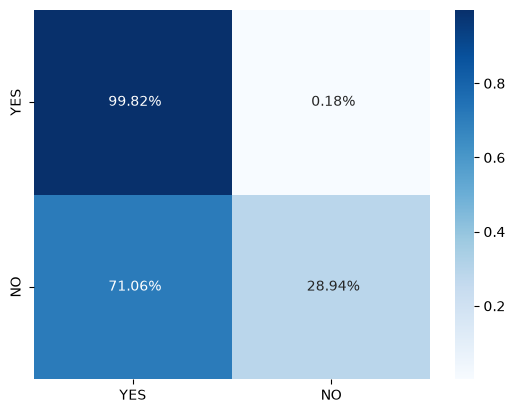

In [ ]:
y_pred = model.predict(x_val)
cm = confusion_matrix(y_val, y_pred, normalize='true')

sns.heatmap(
    cm,
    cmap='Blues',
    fmt =" .2%",
    annot=True,
    xticklabels=["YES", "NO"],
    yticklabels=["YES", "NO"]
)

In [ ]:
df_test = df_test.drop(columns=['is_fraud'])
out = model.predict_proba(df_test)[:,1]
out
df_final = pd.DataFrame(
    {
        "id": ids,
        "is_fraud": out
    }
)
df_final.to_csv("../2026_11_kaggle/solved_04.csv", index=False)